# Predicting Financial Stress Events using 20-day Rolling Volatility as a Stress Proxy.

In [ ]:
SEED = 23
# --- ENV FIRST ---
import os
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
# --- IMPORTS ---
import random
import numpy as np
import tensorflow as tf
# --- TF CONFIG ---
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.set_visible_devices([], 'GPU')
# --- SEEDS ---
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
# --- RESET ---
tf.keras.backend.clear_session()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import recall_score, f1_score, roc_auc_score, confusion_matrix, accuracy_score, roc_curve, precision_score
import itertools
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
try:
  import keras_tuner as kt
except:
  !pip install keras-tuner
  import keras_tuner as kt
from google.colab import files
from google.colab import drive
import pandas as pd
import io
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


Build a function to import data to the notebook.

In [ ]:
def import_data(file_path):
  try:
    drive.mount('/content/drive', force_remount=True)
    # Check if file exists
    if os.path.exists(file_path):
      df = pd.read_parquet(file_path)
      print(f"Loaded dataframe from Drive ({file_path})")
    else:
      raise FileNotFoundError(f"File not found at {file_path}")

  except Exception as e:
    print(f"Drive not available or file missing: {e}")
    print("Please upload dataframe manually.")
    uploaded = files.upload()

    # Automatically read the uploaded file
    file_name = list(uploaded.keys())[0]  # pick the first uploaded file
    try:
      df = pd.read_parquet(io.BytesIO(uploaded[file_name]))
    except:
      print("Wrong file extension. Parquet file required.")
    print(f"Loaded {file_name} from manual upload.")
    return df

Import the dataframe with the volatility (predictor) and the Systemic Stress Events variable (target), df_model_2.parquet, available in the <a href='https://github.com/SebastianoDenegri/vietnam-systemic-risk-index/tree/main/data/machine_learning'>data/machine_learning</a> subdirectory.

In [ ]:
file_path = "..."
df_model_2 = import_data(file_path)

Drive not available or file missing: Error: credential propagation was unsuccessful
Please upload dataframe manually.


Saving df_model_2.parquet to df_model_2.parquet
Loaded df_model_2.parquet from manual upload.


In [ ]:
# align the dataframe at the same starting date of the VSRI
df_model_2 = df_model_2.loc['2017-01-03':].dropna()

In [ ]:
df_model_2.shape

(2384, 2)

Split the data in training (before 31st Match 2024) and test (after 31st Match 2024) set and apply purging (20 days).

In [ ]:
# split data in training and test set and apply purging
split_date = "2024-03-31"
purge = 20
train_2 = df_model_2.loc[:split_date].iloc[:-purge]
test_2  = df_model_2[df_model_2.index > split_date]
X_train_2 = train_2[["vn_volatility"]]
y_train_2 = train_2["systemic_stress_event"]
X_test_2  = test_2[["vn_volatility"]]
y_test_2  = test_2["systemic_stress_event"]

In [ ]:
print(X_train_2.shape, y_train_2.shape, X_test_2.shape, y_test_2.shape)

(1864, 1) (1864,) (500, 1) (500,)


In [ ]:
y_train_2.value_counts()

,count
systemic_stress_event,
0,1727
1,137


In [ ]:
y_test_2.value_counts()

,count
systemic_stress_event,
0,475
1,25


Build functions to fit a given model on training data and output out-of-sample predictions, class probabilities, as well as the following metrics estimated on test data:
- Recall
- F1 score
- ROC AUC
- Confusion Matrix.

In [ ]:
def train_classifier(model, X_train, y_train, X_test, y_test, X_val=False, y_val=False, threshold=0.5, early_stopping=False):
  is_keras = hasattr(model, "fit") and hasattr(model, "predict") and not hasattr(model, "predict_proba")
  if is_keras:
    if early_stopping:
      model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, class_weight=class_weight, validation_data=(X_val, y_val), shuffle=False, callbacks=[combined_metric, es])
    else:
      model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, class_weight=class_weight, validation_data=(X_val, y_val), shuffle=False)
    y_score = model.predict(X_test).ravel()
    y_pred = (y_score >= threshold).astype(int)
  else:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

  # Output Following Metrics:
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_score)
  cm = confusion_matrix(y_test, y_pred)
  precision = precision_score(y_test, y_pred, zero_division=0)
  pr_auc = average_precision_score(y_test, y_score)

  return recall, precision, f1, pr_auc, roc_auc, cm, y_score, y_pred

In [ ]:
def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
  if normalize:
    cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    print("Normalized confusion matrix")
  else:
    print('Confusion matrix, without normalization')

  print(cm)
  plt.imshow(cm, interpolation='nearest', cmap=cmap)
  plt.title(title)
  plt.colorbar()
  tick_marks = np.arange(len(classes))
  plt.xticks(tick_marks, classes)#, rotation=45)
  plt.yticks(tick_marks, classes)
  fmt = '.2f' if normalize else 'd'
  thresh = cm.max() / 2.
  for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, format(cm[i, j], fmt),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

  plt.tight_layout()
  plt.ylabel('True label')
  plt.xlabel('Predicted label')

In [ ]:
# Build a bootsrap function for estimating 95% confidence intervals
def bootstrap_metrics(y_true, y_pred, y_score, n_bootstrap=5000, random_state=23):
  rng = np.random.default_rng(random_state)
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)
  y_score = np.asarray(y_score)
  n = len(y_true)
  bootstrap_results = []

  for _ in range(n_bootstrap):
    # Resample test observations with replacement
    idx = rng.integers(0, n, size=n)

    y_true_boot = y_true[idx]
    y_pred_boot = y_pred[idx]
    y_score_boot = y_score[idx]

    # Skip samples containing only one class
    if len(np.unique(y_true_boot)) < 2:
      continue

    recall = recall_score(y_true_boot, y_pred_boot)
    precision = precision_score(y_true_boot, y_pred_boot)
    f1 = f1_score(y_true_boot, y_pred_boot)
    pr_auc = average_precision_score(y_true_boot, y_score_boot)
    roc_auc = roc_auc_score(y_true_boot, y_score_boot)

    bootstrap_results.append([recall, precision, f1, pr_auc, roc_auc])

  bootstrap_results = np.array(bootstrap_results)
  metrics = ["Recall", "Precision", "F1-Score", "PR-AUC", "ROC-AUC"]
  results = []

  for i, metric in enumerate(metrics):
    estimate = [recall_score(y_true, y_pred),
                precision_score(y_true, y_pred, zero_division=0),
                f1_score(y_true, y_pred),
                average_precision_score(y_true, y_score),
                roc_auc_score(y_true, y_score)][i]

    lower = np.percentile(bootstrap_results[:, i], 2.5)
    upper = np.percentile(bootstrap_results[:, i], 97.5)

    results.append([estimate, lower, upper])

  return pd.DataFrame(results, index=metrics, columns=["Estimate", "CI Lower", "CI Upper"])

## 5.1. Logistic Regression.

In [ ]:
lr_model_2 = LogisticRegression(class_weight="balanced")
lr_results_2 = train_classifier(lr_model_2, X_train_2, y_train_2, X_test_2, y_test_2)

In [ ]:
lr_recall_2, lr_precision_2, lr_f1_2, lr_pr_auc_2, lr_roc_auc_2, lr_cm_2, lr_probs_2, lr_preds_2 = lr_results_2

Confusion matrix, without normalization
[[475   0]
 [ 25   0]]


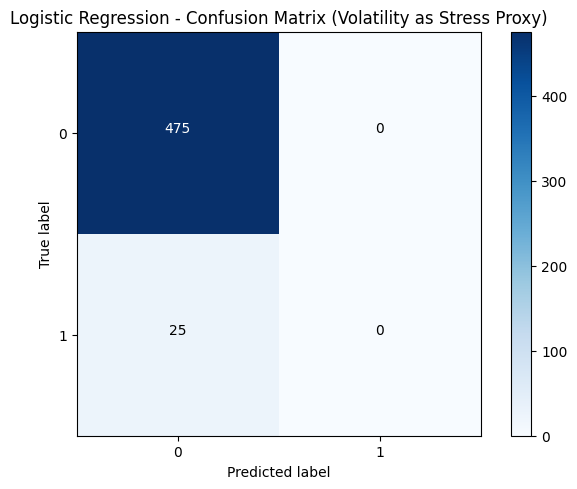

In [ ]:
plot_confusion_matrix(cm=lr_cm_2, classes=[0,1], normalize= False,  title='Logistic Regression - Confusion Matrix (Volatility as Stress Proxy)')

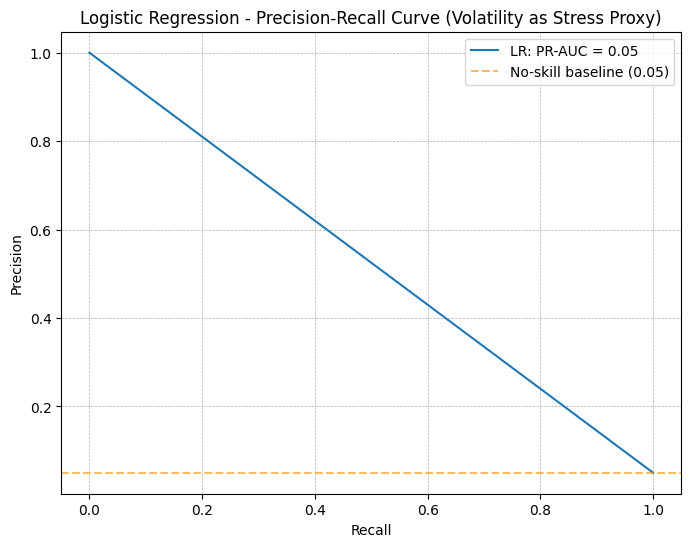

In [ ]:
baseline = y_test_2.mean()
precision, recall, _ = precision_recall_curve(y_test_2, lr_probs_2)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'LR: PR-AUC = {lr_pr_auc_2:.2f}')
plt.axhline(baseline, linestyle='--', alpha=0.6, color='darkorange', label=f'No-skill baseline ({baseline:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Logistic Regression - Precision-Recall Curve (Volatility as Stress Proxy)')
plt.legend()
plt.grid(True, linestyle='--', linewidth=.5)
plt.show()

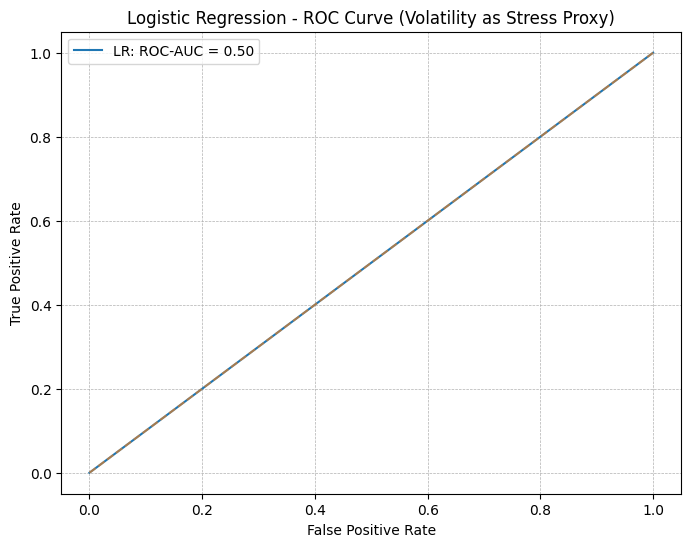

In [ ]:
fpr, tpr, thr = roc_curve(y_test_2, lr_probs_2)
# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"LR: ROC-AUC = {lr_roc_auc_2:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", alpha=0.6)  # random baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve (Volatility as Stress Proxy)")
plt.legend()
plt.grid(True, linestyle='--', linewidth=.5)
plt.show()

In [ ]:
lr_results_2 = {'Recall': lr_recall_2, 'Precision': lr_precision_2, 'F1-Score': lr_f1_2, 'PR-AUC': lr_pr_auc_2, 'ROC-AUC': lr_roc_auc_2}
lr_results_2 = pd.DataFrame(lr_results_2, index=['Logistic Regression (Volatility as Stress Proxy)'])

In [ ]:
lr_results_2

,Recall,Precision,F1-Score,PR-AUC,ROC-AUC
Logistic Regression (Volatility as Stress Proxy),0.0,0.0,0.0,0.05,0.5


In [ ]:
bench_2_lr_ci = bootstrap_metrics(y_test_2, lr_preds_2, lr_probs_2)
round(bench_2_lr_ci, 2)

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3

,Estimate,CI Lower,CI Upper
Recall,0.00,0.00,0.00
Precision,0.00,0.00,0.00
F1-Score,0.00,0.00,0.00
PR-AUC,0.05,0.03,0.07
ROC-AUC,0.50,0.50,0.50


## 5.2. Support Vector Machines.

In [ ]:
svm_model_2 = SVC(C=0.5, kernel='rbf', probability=True, class_weight="balanced")
svm_results_2 = train_classifier(svm_model_2, X_train_2, y_train_2, X_test_2, y_test_2)

In [ ]:
svm_recall_2, svm_precision_2, svm_f1_2, svm_pr_auc_2, svm_roc_auc_2, svm_cm_2, svm_probs_2, svm_preds_2 = svm_results_2

Confusion matrix, without normalization
[[335 140]
 [ 15  10]]


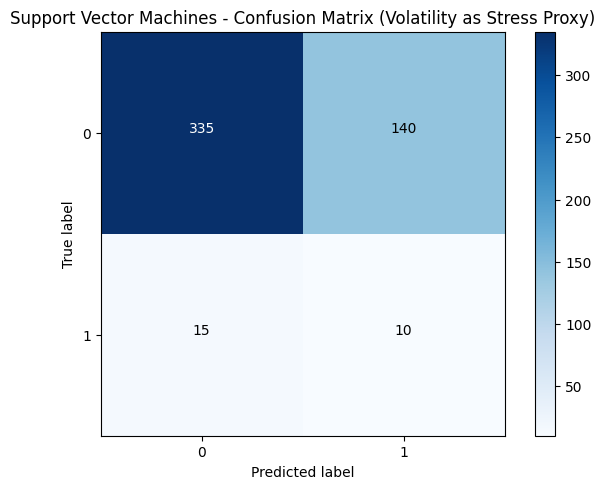

In [ ]:
plot_confusion_matrix(cm=svm_cm_2, classes=[0,1], normalize= False,  title='Support Vector Machines - Confusion Matrix (Volatility as Stress Proxy)')

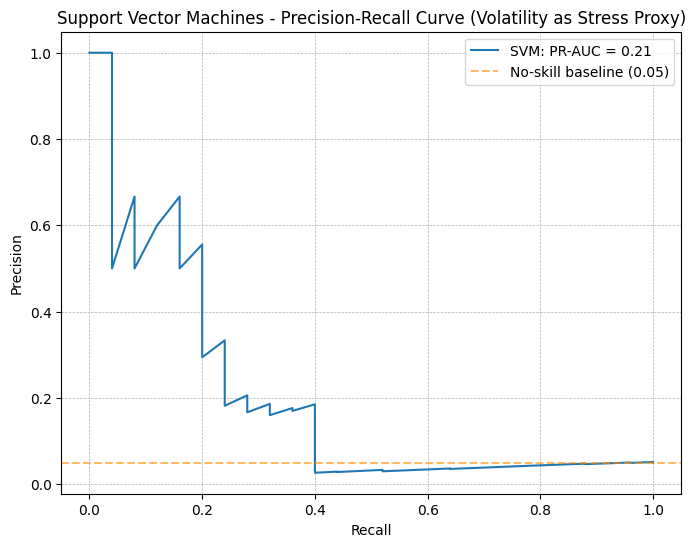

In [ ]:
precision, recall, _ = precision_recall_curve(y_test_2, svm_probs_2)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'SVM: PR-AUC = {svm_pr_auc_2:.2f}')
plt.axhline(baseline, linestyle='--', alpha=0.6, color='darkorange', label=f'No-skill baseline ({baseline:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Support Vector Machines - Precision-Recall Curve (Volatility as Stress Proxy)')
plt.legend()
plt.grid(True, linestyle='--', linewidth=.5)
plt.show()

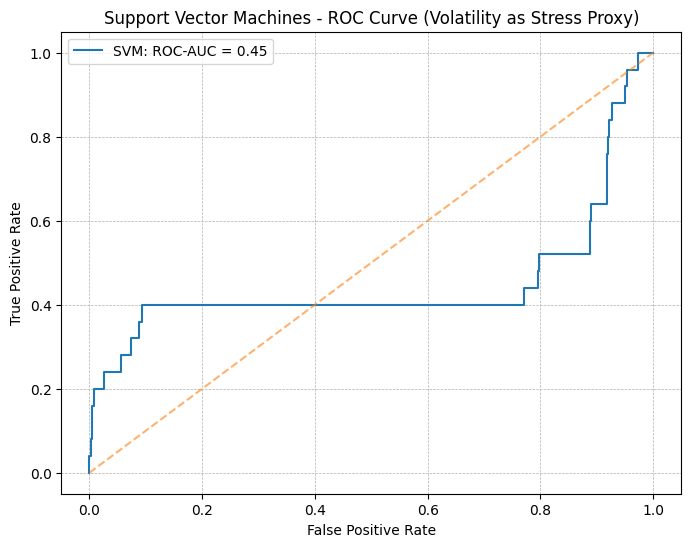

In [ ]:
fpr, tpr, thr = roc_curve(y_test_2, svm_probs_2)
# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"SVM: ROC-AUC = {svm_roc_auc_2:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", alpha=0.6)  # random baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Support Vector Machines - ROC Curve (Volatility as Stress Proxy)")
plt.legend()
plt.grid(True, linestyle='--', linewidth=.5)
plt.show()

In [ ]:
svm_results_2 = pd.DataFrame({'Recall': svm_recall_2, 'Precision': svm_precision_2, 'F1-Score': svm_f1_2, 'PR-AUC': svm_pr_auc_2, 'ROC-AUC': svm_roc_auc_2},
                             index=['Support Vector Machines (Volatility as Stress Proxy)'])
svm_results_2

,Recall,Precision,F1-Score,PR-AUC,ROC-AUC
Support Vector Machines (Volatility as Stress Proxy),0.4,0.066667,0.114286,0.207122,0.448589


In [ ]:
bench_2_svm_ci = bootstrap_metrics(y_test_2, svm_preds_2, svm_probs_2)
round(bench_2_svm_ci, 2)

,Estimate,CI Lower,CI Upper
Recall,0.40,0.22,0.60
Precision,0.07,0.03,0.11
F1-Score,0.11,0.05,0.18
PR-AUC,0.21,0.08,0.40
ROC-AUC,0.45,0.29,0.62


## 5.3. Long Short-Term Memory (LSTM) Networks.

The data sets for the LSTM network are defined as follows:
- Training data: until 1st March 2023 (excluded)
- Validation data: from 1st March 2023 until 31st March 2024
- Test data: from 1st April 2024

We apply a 20-day purge period between training and validation as well as validation and test sets.  
Sequence length: 60 days (a quarter of trading activities).

In [ ]:
timesteps = 60
split_idx = pd.Timestamp("2023-03-01")
X_train_lstm_bench_2 = X_train_2[X_train_2.index < split_idx].iloc[:-purge]
y_train_lstm_bench_2 = y_train_2[y_train_2.index < split_idx].iloc[:-purge]
X_val_lstm_bench_2 = X_train_2.loc[split_idx:]
y_val_lstm_bench_2 = y_train_2.loc[split_idx:]

X_train_values_bench_2 = X_train_lstm_bench_2.values
y_train_values_bench_2 = y_train_lstm_bench_2.values
X_test_values_bench_2 = X_test_2.values
y_test_values_bench_2 = y_test_2.values
X_val_values_bench_2 = X_val_lstm_bench_2.values
y_val_values_bench_2 = y_val_lstm_bench_2.values
X_train_seq_bench_2 = []
y_train_seq_bench_2 = []
X_test_seq_bench_2 = []
y_test_seq_bench_2 = []
X_val_seq_bench_2 = []
y_val_seq_bench_2 = []
for i in range(timesteps, len(X_train_values_bench_2)):
  X_train_seq_bench_2.append(X_train_values_bench_2[i - timesteps:i])
  y_train_seq_bench_2.append(y_train_values_bench_2[i])
for i in range(timesteps, len(X_test_values_bench_2)):
  X_test_seq_bench_2.append(X_test_values_bench_2[i - timesteps:i])
  y_test_seq_bench_2.append(y_test_values_bench_2[i])
for i in range(timesteps, len(X_val_values_bench_2)):
  X_val_seq_bench_2.append(X_val_values_bench_2[i - timesteps:i])
  y_val_seq_bench_2.append(y_val_values_bench_2[i])

X_train_seq_bench_2 = np.array(X_train_seq_bench_2)
y_train_seq_bench_2 = np.array(y_train_seq_bench_2)
X_test_seq_bench_2 = np.array(X_test_seq_bench_2)
y_test_seq_bench_2 = np.array(y_test_seq_bench_2)
X_val_seq_bench_2 = np.array(X_val_seq_bench_2)
y_val_seq_bench_2 = np.array(y_val_seq_bench_2)

In [ ]:
print(X_train_seq_bench_2.shape,
      y_train_seq_bench_2.shape,
      X_val_seq_bench_2.shape,
      y_val_seq_bench_2.shape,
      X_test_seq_bench_2.shape,
      y_test_seq_bench_2.shape)

(1522, 60, 1) (1522,) (202, 60, 1) (202,) (440, 60, 1) (440,)


In [ ]:
np.unique(y_train_seq_bench_2, return_counts=True)

(array([0, 1]), array([1395,  127]))

In [ ]:
np.unique(y_val_seq_bench_2, return_counts=True)

(array([0, 1]), array([192,  10]))

In [ ]:
np.unique(y_test_seq_bench_2, return_counts=True)

(array([0, 1]), array([415,  25]))

In [ ]:
tf.keras.backend.clear_session()
input_shape = X_train_seq_bench_2.shape[1:]  # (60, num_features)
lstm_model_bench_2 = keras.Sequential()
lstm_model_bench_2.add(layers.LSTM(128, return_sequences=True, input_shape=input_shape))
lstm_model_bench_2.add(layers.Dropout(0.5))
lstm_model_bench_2.add(layers.LSTM(128, return_sequences=True))
lstm_model_bench_2.add(layers.LSTM(16, return_sequences=True))
lstm_model_bench_2.add(layers.LSTM(8, return_sequences=True))
lstm_model_bench_2.add(layers.Dropout(0.3))
lstm_model_bench_2.add(layers.LSTM(8, return_sequences=False))
lstm_model_bench_2.add(layers.Dropout(0.3))
# Dense layers
lstm_model_bench_2.add(layers.Dense(16, activation="relu"))
lstm_model_bench_2.add(layers.Dense(1, activation="sigmoid"))
# Compile
lstm_model_bench_2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="pr_auc", curve="PR"),
        keras.metrics.AUC(name="roc_auc", curve="ROC"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.Precision(name="precision")])

lstm_model_bench_2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 60, 16)         │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 60, 8)          │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 8)              │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 208,929 (816.13 KB)

 Trainable params: 208,929 (816.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class CombinedMetric(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
    logs = logs or {}
    recall = logs.get("val_recall", 0)
    pr_auc = logs.get("val_pr_auc", 0)
    logs["val_combined"] = 0.3 * recall + 0.7 * pr_auc

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
combined_metric = CombinedMetric()
es = tf.keras.callbacks.EarlyStopping(monitor="val_combined", mode="max", patience=50, restore_best_weights=True, verbose=1)
classes = np.unique(y_train_seq_bench_2)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_seq_bench_2)
class_weight = dict(zip(classes, weights))
epochs=200
batch_size=32

lstm_results_bench_2 = train_classifier(lstm_model_bench_2, X_train_seq_bench_2, y_train_seq_bench_2, X_test_seq_bench_2, y_test_seq_bench_2, X_val=X_val_seq_bench_2, y_val=y_val_seq_bench_2, early_stopping=True)

Epoch 1/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 17s 193ms/step - loss: 0.6934 - pr_auc: 0.0736 - precision: 0.0213 - recall: 0.0079 - roc_auc: 0.4386 - val_loss: 0.6899 - val_pr_auc: 0.0495 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5000 - val_combined: 0.0347
Epoch 2/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 178ms/step - loss: 0.6932 - pr_auc: 0.0724 - precision: 0.0952 - recall: 0.0315 - roc_auc: 0.4293 - val_loss: 0.6904 - val_pr_auc: 0.0495 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5000 - val_combined: 0.0347
Epoch 3/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 176ms/step - loss: 0.6932 - pr_auc: 0.0800 - precision: 0.0823 - recall: 0.1024 - roc_auc: 0.4805 - val_loss: 0.6915 - val_pr_auc: 0.0495 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5000 - val_combined: 0.0347
Epoch 4/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 153ms/step - loss: 0.6933 - pr_auc: 0.0825 - precision: 0.0847 - recall: 0.1260 - roc_auc: 0.4941 - val_loss: 0.6899 - val

In [ ]:
lstm_recall_bench_2, lstm_precision_bench_2, lstm_f1_bench_2, lstm_pr_auc_bench_2, lstm_roc_auc_bench_2, lstm_cm_bench_2, lstm_probs_bench_2, lstm_preds_bench_2 = lstm_results_bench_2

Confusion matrix, without normalization
[[  0 415]
 [  0  25]]


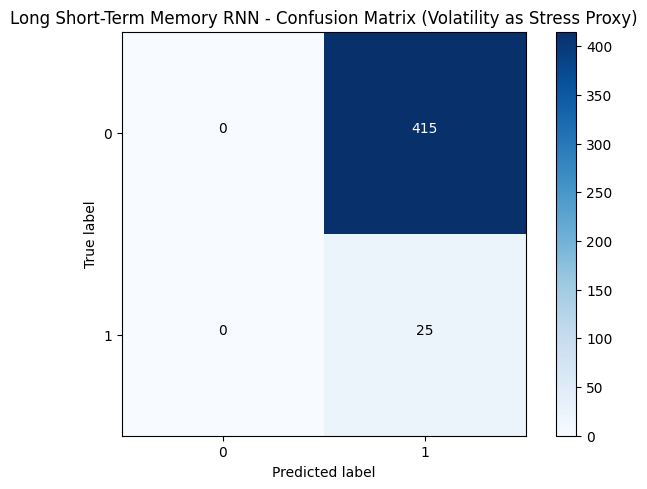

In [ ]:
plot_confusion_matrix(cm=lstm_cm_bench_2, classes=[0,1], normalize= False,  title='Long Short-Term Memory RNN - Confusion Matrix (Volatility as Stress Proxy)')

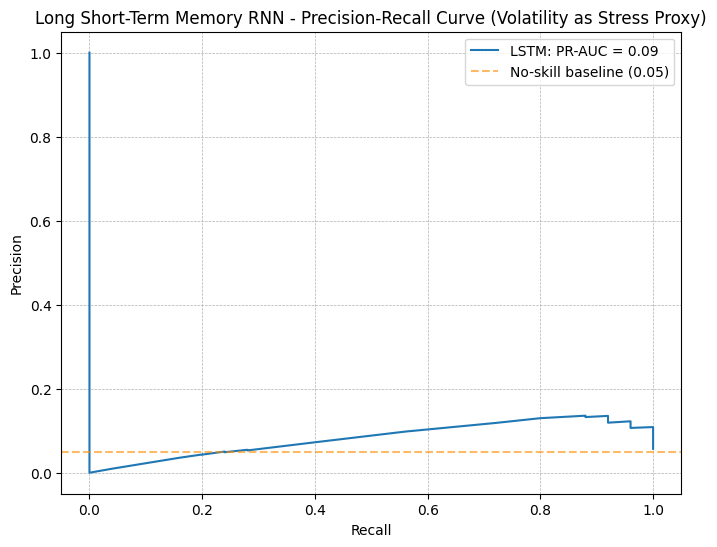

In [ ]:
precision, recall, _ = precision_recall_curve(y_test_seq_bench_2, lstm_probs_bench_2)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'LSTM: PR-AUC = {lstm_pr_auc_bench_2:.2f}')
plt.axhline(baseline, linestyle='--', alpha=0.6, color='darkorange', label=f'No-skill baseline ({baseline:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Long Short-Term Memory RNN - Precision-Recall Curve (Volatility as Stress Proxy)')
plt.legend()
plt.grid(True, linestyle='--', linewidth=.5)
plt.show()

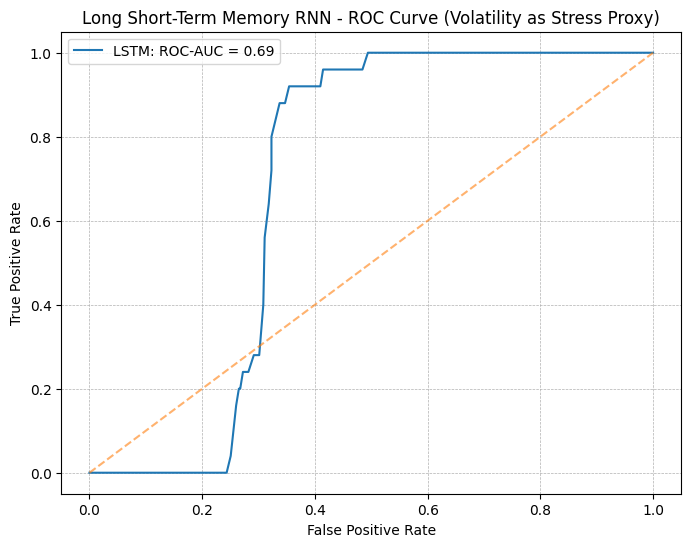

In [ ]:
fpr, tpr, thr = roc_curve(y_test_seq_bench_2, lstm_probs_bench_2)
# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"LSTM: ROC-AUC = {lstm_roc_auc_bench_2:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", alpha=0.6)  # random baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Long Short-Term Memory RNN - ROC Curve (Volatility as Stress Proxy)")
plt.legend()
plt.grid(True, linestyle='--', linewidth=.5)
plt.show()

In [ ]:
bench_2_lstm_ci = bootstrap_metrics(y_test_seq_bench_2, lstm_preds_bench_2, lstm_probs_bench_2)
round(bench_2_lstm_ci, 2)

,Estimate,CI Lower,CI Upper
Recall,1.00,1.00,1.00
Precision,0.06,0.04,0.08
F1-Score,0.11,0.07,0.15
PR-AUC,0.09,0.06,0.13
ROC-AUC,0.69,0.64,0.73


In [ ]:
lstm_results_bench_2 = pd.DataFrame({'Recall': lstm_recall_bench_2, 'Precision': lstm_precision_bench_2, 'F1-Score': lstm_f1_bench_2, 'PR-AUC': lstm_pr_auc_bench_2, 'ROC-AUC': lstm_roc_auc_bench_2},
                                    index=['Long Short-Term Memory RNN (Volatility as Stress Proxy)'])
ml_results_bench_2 = pd.concat([lr_results_2.round(2), svm_results_2.round(2), lstm_results_bench_2.round(2)])
ml_results_bench_2

,Recall,Precision,F1-Score,PR-AUC,ROC-AUC
Logistic Regression (Volatility as Stress Proxy),0.0,0.00,0.00,0.05,0.50
Support Vector Machines (Volatility as Stress Proxy),0.4,0.07,0.11,0.21,0.45
Long Short-Term Memory RNN (Volatility as Stress Proxy),1.0,0.06,0.11,0.09,0.69


Logistic Regression and SVM perform comparably to, or worse than, a random classifier in terms of ROC-AUC: Logistic Regression predicts every observation as negative, whilst SVM tries to find a discriminant boundary but results are overall poor. LSTM is the only model, across the models trained on volatility, that outperforms random guessing, achieving a ROC-AUC of 0.69; although the LSTM predicts all observations as positive, a ROC-AUC of 0.69 is actually quite
decent, so it seems that LSTM managed to assign reasonably informative class
probabilities to the test samples, extracting meaningful signals contained in a stress proxy such as market volatility.

In [ ]:
bench_2_bootstrap_results_all = {}
bench_2_bootstrap_results_all["Logistic Regression (Volatility as Stress Proxy)"] = bench_2_lr_ci
bench_2_bootstrap_results_all["SVM (Volatility as Stress Proxy)"] = bench_2_svm_ci
bench_2_bootstrap_results_all["LSTM (Volatility as Stress Proxy)"] = bench_2_lstm_ci

bench_2_ci_consolidated = pd.DataFrame({model: {metric: f"{row['Estimate']:.2f} [{row['CI Lower']:.2f}, {row['CI Upper']:.2f}]" for metric, row in results.iterrows()}
                                     for model, results in bench_2_bootstrap_results_all.items()}).T
bench_2_ci_consolidated.index.name = "Model"
bench_2_ci_consolidated

,Recall,Precision,F1-Score,PR-AUC,ROC-AUC
Model,,,,,
Logistic Regression (Volatility as Stress Proxy),"0.00 [0.00, 0.00]","0.00 [0.00, 0.00]","0.00 [0.00, 0.00]","0.05 [0.03, 0.07]","0.50 [0.50, 0.50]"
SVM (Volatility as Stress Proxy),"0.40 [0.22, 0.60]","0.07 [0.03, 0.11]","0.11 [0.05, 0.18]","0.21 [0.08, 0.40]","0.45 [0.29, 0.62]"
LSTM (Volatility as Stress Proxy),"1.00 [1.00, 1.00]","0.06 [0.04, 0.08]","0.11 [0.07, 0.15]","0.09 [0.06, 0.13]","0.69 [0.64, 0.73]"


Export the results of the models trained on a conventional stress proxy (volatility) for financial stress events predictions.

```python
ml_results_bench_2.to_csv("ml_results_bench_2.csv", index=True)
files.download("ml_results_bench_2.csv")
ml_results_bench_2.to_parquet("ml_results_bench_2.parquet", index=True)
files.download("ml_results_bench_2.parquet")
```

```python
bench_2_ci_consolidated.to_parquet("bench_2_ci_consolidated.parquet", index=True)
files.download("bench_2_ci_consolidated.parquet")
```

We refer to the project report for a discussion on the results of the machine learning models trained in this notebook compared with the VSRI-trained models' results.  
We refer also to the <a href='https://github.com/SebastianoDenegri/vietnam-systemic-risk-index/tree/main/notebooks/appendix_c'>notebooks/appendix_c</a> sub-directory, containing the notebooks for the LSTM robustness analysis, where we retrained the LSTM networks across five additional random seeds, to test how robust the LSTM network results are to changes in the initialized weights.